# FinMark Corporation
## Project Data Preparation and Exploratory Data Analysis (EDA)

This notebook documents the **end-to-end data preparation workflow** for FinMark’s datasets:

- `Transaction_Data.csv`
- `Customer_Feedback_Data.csv`
- `Product_Offering_Data.csv`

The focus here is **cleaning, preprocessing, integration, and EDA**.  
A separate notebook can be used later for **modeling-oriented feature engineering** (e.g., clustering-ready customer feature table).

**Outputs (saved locally):**
- `cleaned/transactions_cleaned.csv`
- `cleaned/feedback_cleaned.csv`
- `cleaned/feedback_customer_summary.csv`
- `cleaned/products_cleaned.csv`
- `cleaned/merged_transactions_feedback.csv`


## 0) Setup and conventions

### What this section sets up
- Core Python libraries (NumPy, pandas) for data wrangling  
- Matplotlib for plotting  
- Display and formatting settings for consistent outputs

### “Clean-looking” data standard for this submission
- Numeric outputs displayed at **2 decimal places** in the notebook for readability
- Exported “cleaned” CSVs are also **rounded to 2 decimals** for uniform presentation (without changing business meaning materially for this milestone)


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import datetime
import warnings
warnings.filterwarnings("ignore")

# Display options (readability)
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 140)
pd.options.display.float_format = "{:,.2f}".format


## 1) Load datasets

### What we do here
- Load the three provided CSV datasets
- Keep raw copies intact and work on cleaned copies to preserve traceability


In [2]:

DATA_DIR_CANDIDATES = [Path("."), Path("/mnt/data")]

def resolve_path(filename: str) -> Path:
    for d in DATA_DIR_CANDIDATES:
        p = d / filename
        if p.exists():
            return p
    raise FileNotFoundError(f"Could not find {filename} in {DATA_DIR_CANDIDATES}")

txn_path  = resolve_path("Transaction_Data.csv")
fb_path   = resolve_path("Customer_Feedback_Data.csv")
prod_path = resolve_path("Product_Offering_Data.csv")

transaction_raw = pd.read_csv(txn_path)
feedback_raw    = pd.read_csv(fb_path)
product_raw     = pd.read_csv(prod_path)

print("Loaded datasets:")
print(f"- Transactions: {transaction_raw.shape} from {txn_path}")
print(f"- Feedback:     {feedback_raw.shape} from {fb_path}")
print(f"- Products:     {product_raw.shape} from {prod_path}")


Loaded datasets:
- Transactions: (5050, 5) from Transaction_Data.csv
- Feedback:     (5050, 4) from Customer_Feedback_Data.csv
- Products:     (15, 6) from Product_Offering_Data.csv


## 2) Quick audit utilities (data quality snapshot)

### Why we do an audit first
Before cleaning, we generate a consistent snapshot of:
- data types  
- missingness (counts and %)  
- full-row duplicates  
- a quick preview  

This helps justify cleaning decisions later in the write-up.


In [3]:

def standardize_columns(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out.columns = [c.strip().replace("\ufeff", "") for c in out.columns]
    return out

def audit_df(df: pd.DataFrame, name: str, head_n: int = 5) -> None:
    df = standardize_columns(df)
    print(f"\n{name}")
    print("-" * len(name))
    print(f"Shape: {df.shape}")
    display(df.head(head_n))

    print("\nDtypes:")
    display(df.dtypes.to_frame("dtype"))

    missing = df.isna().sum().to_frame("missing_count")
    missing["missing_pct"] = (missing["missing_count"] / len(df)).round(4)
    missing = missing.sort_values(["missing_count", "missing_pct"], ascending=False)
    print("\nMissing values:")
    display(missing)

    dup_rows = df.duplicated().sum()
    print(f"\nDuplicate rows: {dup_rows:,}")


In [4]:

audit_df(transaction_raw, "Transactions (raw)")
audit_df(feedback_raw, "Customer Feedback (raw)")
audit_df(product_raw, "Product Offering (raw)")



Transactions (raw)
------------------
Shape: (5050, 5)


,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Amount,Transaction_Type
0,1,393,2023-01-01 00:00:00,"3,472.00",Purchase
1,2,826,2023-01-01 01:00:00,NaN,Bill Payment
2,3,916,2023-01-01 02:00:00,10.00,Purchase
3,4,109,2023-01-01 03:00:00,72.00,Investment
4,5,889,2023-01-01 04:00:00,"1,793.00",Investment



Dtypes:


,dtype
Transaction_ID,int64
Customer_ID,int64
Transaction_Date,object
Transaction_Amount,float64
Transaction_Type,object



Missing values:


,missing_count,missing_pct
Transaction_Amount,100,0.02
Transaction_ID,0,0.00
Customer_ID,0,0.00
Transaction_Date,0,0.00
Transaction_Type,0,0.00


... (9 outputs left out)

,dtype
Product_ID,int64
Product_Name,object
Product_Type,object
Risk_Level,object
Target_Age_Group,float64
Target_Income_Group,object



Missing values:


,missing_count,missing_pct
Target_Age_Group,15,1.00
Product_ID,0,0.00
Product_Name,0,0.00
Product_Type,0,0.00
Risk_Level,0,0.00
Target_Income_Group,0,0.00



Duplicate rows: 5


## 3) Cleaning and preprocessing

This section applies systematic cleaning per dataset.  
Key requirements addressed:
- missing values  
- duplicate records  
- inconsistent formats  
- outlier detection and treatment (numeric fields)


### 3.1 Transactions — cleaning decisions

**Decisions and rationale**
1. **Duplicates:** remove **full-row duplicates** to avoid double-counting transactions.  
2. **Dates:** parse `Transaction_Date` to datetime to enable time-based EDA.  
3. **Amounts:** enforce numeric type; if missing, impute using:
   - median within `Transaction_Type` (more context-aware), falling back to overall median.  
4. **Outliers:** detect outliers in `Transaction_Amount` using the **IQR rule**, then **cap** (winsorize) values outside bounds rather than removing rows.  
   - Rationale: preserves transaction volume while reducing extreme value distortion in EDA.


In [5]:

transactions = standardize_columns(transaction_raw)

# Track counts for reporting
txn_full_dupes_removed = int(transactions.duplicated().sum())

# --- Standardize formats ---
transactions["Transaction_Date"] = pd.to_datetime(transactions["Transaction_Date"], errors="coerce")
transactions["Transaction_Type"] = transactions["Transaction_Type"].astype(str).str.strip().str.title()
transactions["Transaction_Amount"] = pd.to_numeric(transactions["Transaction_Amount"], errors="coerce")

# --- Remove full-row duplicates ---
transactions = transactions.drop_duplicates()

# --- Missing value handling (Transaction_Amount) ---
transactions["amount_was_missing"] = transactions["Transaction_Amount"].isna().astype(int)
txn_missing_amount = int(transactions["amount_was_missing"].sum())

type_medians = transactions.groupby("Transaction_Type")["Transaction_Amount"].median()
overall_median = transactions["Transaction_Amount"].median()

def impute_amount(row):
    if pd.isna(row["Transaction_Amount"]):
        m = type_medians.get(row["Transaction_Type"], np.nan)
        return overall_median if pd.isna(m) else m
    return row["Transaction_Amount"]

transactions["Transaction_Amount"] = transactions.apply(impute_amount, axis=1)

# --- Outlier detection & treatment (IQR) ---
def iqr_bounds(s: pd.Series, k: float = 1.5):
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - k * iqr
    upper = q3 + k * iqr
    return lower, upper

amt_lower, amt_upper = iqr_bounds(transactions["Transaction_Amount"])

transactions["amount_outlier_flag"] = (
    (transactions["Transaction_Amount"] < amt_lower) | (transactions["Transaction_Amount"] > amt_upper)
).astype(int)

txn_outlier_count = int(transactions["amount_outlier_flag"].sum())

# Preserve raw amount before capping
transactions["Transaction_Amount_Raw"] = transactions["Transaction_Amount"]
transactions["Transaction_Amount"] = transactions["Transaction_Amount"].clip(lower=amt_lower, upper=amt_upper)

print(f"Transactions: removed {txn_full_dupes_removed:,} full-row duplicates.")
print(f"Transactions: imputed {txn_missing_amount:,} missing Transaction_Amount values (type-median → overall median fallback).")
print(f"Transactions: detected {txn_outlier_count:,} IQR outliers; applied capping to IQR bounds.")
print(f"IQR bounds: lower={amt_lower:.2f}, upper={amt_upper:.2f}")
print("Null Transaction_Date after parsing:", int(transactions['Transaction_Date'].isna().sum()))

display(transactions.head())


Transactions: removed 50 full-row duplicates.
Transactions: imputed 100 missing Transaction_Amount values (type-median → overall median fallback).
Transactions: detected 10 IQR outliers; applied capping to IQR bounds.
IQR bounds: lower=-2373.00, upper=7315.00
Null Transaction_Date after parsing: 0


,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Amount,Transaction_Type,amount_was_missing,amount_outlier_flag,Transaction_Amount_Raw
0,1,393,2023-01-01 00:00:00,"3,472.00",Purchase,0,0,"3,472.00"
1,2,826,2023-01-01 01:00:00,"2,485.00",Bill Payment,1,0,"2,485.00"
2,3,916,2023-01-01 02:00:00,10.00,Purchase,0,0,10.00
3,4,109,2023-01-01 03:00:00,72.00,Investment,0,0,72.00
4,5,889,2023-01-01 04:00:00,"1,793.00",Investment,0,0,"1,793.00"


### 3.2 Customer feedback — cleaning decisions

**Decisions and rationale**
1. **Duplicates:** remove **full-row duplicates** to avoid overweighting repeated identical responses.  
2. **Scores:** convert to numeric and clamp to expected 1–10 range.  
3. **Missing satisfaction score:** impute with:
   - customer-level median (if available), otherwise overall median.  
4. **Aggregation:** because there can be multiple feedback entries per customer, we create a **customer-level summary table** (mean/std and top comment).  
   - Rationale: preserves signal and prevents “random first row” bias during merges.


In [6]:

feedback = standardize_columns(feedback_raw)

fb_full_dupes_removed = int(feedback.duplicated().sum())

# Numeric conversions
feedback["Satisfaction_Score"] = pd.to_numeric(feedback["Satisfaction_Score"], errors="coerce")
feedback["Likelihood_to_Recommend"] = pd.to_numeric(feedback["Likelihood_to_Recommend"], errors="coerce")

# Standardize comment categories
feedback["Feedback_Comments"] = feedback["Feedback_Comments"].astype(str).str.strip().str.title()

# Remove full-row duplicates
feedback = feedback.drop_duplicates()

# Missing satisfaction imputation
feedback["satisfaction_was_missing"] = feedback["Satisfaction_Score"].isna().astype(int)
fb_missing_sat = int(feedback["satisfaction_was_missing"].sum())

cust_median_sat = feedback.groupby("Customer_ID")["Satisfaction_Score"].median()
overall_sat_median = feedback["Satisfaction_Score"].median()

def impute_sat(row):
    if pd.isna(row["Satisfaction_Score"]):
        m = cust_median_sat.get(row["Customer_ID"], np.nan)
        return overall_sat_median if pd.isna(m) else m
    return row["Satisfaction_Score"]

feedback["Satisfaction_Score"] = feedback.apply(impute_sat, axis=1)

# Clamp score ranges (expected 1..10)
feedback["Satisfaction_Score"] = feedback["Satisfaction_Score"].clip(1, 10)
feedback["Likelihood_to_Recommend"] = feedback["Likelihood_to_Recommend"].clip(1, 10)

# Customer-level aggregation for merging
def mode_or_nan(s):
    vc = s.value_counts(dropna=True)
    return vc.index[0] if len(vc) else np.nan

feedback_agg = (
    feedback
    .groupby("Customer_ID", as_index=False)
    .agg(
        feedback_count=("Customer_ID", "size"),
        satisfaction_mean=("Satisfaction_Score", "mean"),
        satisfaction_std=("Satisfaction_Score", "std"),
        ltr_mean=("Likelihood_to_Recommend", "mean"),
        ltr_std=("Likelihood_to_Recommend", "std"),
        top_comment=("Feedback_Comments", mode_or_nan),
    )
)

# Fill std for single-observation customers
feedback_agg["satisfaction_std"] = feedback_agg["satisfaction_std"].fillna(0)
feedback_agg["ltr_std"] = feedback_agg["ltr_std"].fillna(0)

print(f"Feedback: removed {fb_full_dupes_removed:,} full-row duplicates.")
print(f"Feedback: imputed {fb_missing_sat:,} missing Satisfaction_Score values (customer-median → overall median fallback).")
print("Feedback cleaned shape:", feedback.shape)
print("Customer summary shape:", feedback_agg.shape)

display(feedback.head())
display(feedback_agg.head().round(2))


Feedback: removed 81 full-row duplicates.
Feedback: imputed 100 missing Satisfaction_Score values (customer-median → overall median fallback).
Feedback cleaned shape: (4969, 5)
Customer summary shape: (1000, 7)


,Customer_ID,Satisfaction_Score,Feedback_Comments,Likelihood_to_Recommend,satisfaction_was_missing
0,1,10.00,Very Satisfied,9,0
1,2,3.00,Very Satisfied,3,0
2,3,10.00,Very Satisfied,1,0
3,4,7.00,Needs Improvement,4,0
4,5,8.00,Unsatisfactory,7,0


,Customer_ID,feedback_count,satisfaction_mean,satisfaction_std,ltr_mean,ltr_std,top_comment
0,1,2,8.50,2.12,9.00,0.00,Very Satisfied
1,2,3,4.33,2.31,5.00,2.00,Very Satisfied
2,3,3,8.33,2.08,3.67,3.79,Very Satisfied
3,4,6,5.50,2.07,3.33,2.50,Needs Improvement
4,5,9,6.44,2.01,5.67,2.87,Unsatisfactory


### 3.3 Product offering — cleaning decisions

**Decisions and rationale**
1. **Duplicates:** remove full-row duplicates; additionally enforce unique `Product_ID` (keep first) if needed.  
2. **Missing columns:** drop columns with **100% missing values** (no analytical value for this milestone).  
3. **Standardization:** normalize category text (strip + title-case) for consistent EDA.


In [7]:

products = standardize_columns(product_raw)

prod_full_dupes_removed = int(products.duplicated().sum())

# Standardize text fields (if present)
for col in ["Product_Name", "Product_Type", "Risk_Level", "Target_Income_Group"]:
    if col in products.columns:
        products[col] = products[col].astype(str).str.strip().str.title()

# Remove duplicates (full row)
products = products.drop_duplicates()

# Drop columns with 100% missing
all_missing_cols = [c for c in products.columns if products[c].isna().mean() == 1.0]
prod_cols_dropped = all_missing_cols.copy()
if all_missing_cols:
    products = products.drop(columns=all_missing_cols)

# Enforce uniqueness by Product_ID if applicable
prod_id_dupes_removed = 0
if "Product_ID" in products.columns:
    before = len(products)
    products = products.sort_values("Product_ID").drop_duplicates(subset=["Product_ID"], keep="first")
    prod_id_dupes_removed = before - len(products)

print(f"Products: removed {prod_full_dupes_removed:,} full-row duplicates.")
if prod_cols_dropped:
    print("Products: dropped fully-missing columns:", prod_cols_dropped)
if prod_id_dupes_removed:
    print(f"Products: removed {prod_id_dupes_removed:,} duplicate Product_ID rows (kept first).")

display(products)


Products: removed 5 full-row duplicates.
Products: dropped fully-missing columns: ['Target_Age_Group']


,Product_ID,Product_Name,Product_Type,Risk_Level,Target_Income_Group
0,1,Platinum Credit Card,Credit Card,Medium,Medium
1,2,Gold Savings Account,Savings Account,Low,Low
2,3,High-Yield Investment Account,Investment,High,High
3,4,Mortgage Loan,Loan,Medium,High
4,5,Auto Loan,Loan,Medium,Medium
5,6,Personal Loan,Loan,Medium,Low
6,7,Youth Savings Account,Savings Account,Low,Low
7,8,Retirement Investment Fund,Investment,High,High
8,9,Business Loan,Loan,Medium,Medium
9,10,Travel Credit Card,Credit Card,Medium,Medium


## 4) Merge: transactions + customer feedback summary

### Merge strategy and rationale
- We merge **transaction-level** records with a **customer-level** feedback summary using `Customer_ID`.  
- This supports EDA such as “spend vs satisfaction” without creating an inconsistent merge (e.g., joining raw feedback rows directly would multiply records and bias analysis).


In [8]:

merged = transactions.merge(feedback_agg, on="Customer_ID", how="left")

print("Merged shape:", merged.shape)
print("Rows with missing feedback summary:", int(merged["feedback_count"].isna().sum()))

# Basic missingness snapshot (top 20)
missing_merged = merged.isna().sum().to_frame("missing_count")
missing_merged["missing_pct"] = (missing_merged["missing_count"] / len(merged)).round(4)
display(missing_merged.sort_values(["missing_count", "missing_pct"], ascending=False).head(20))

display(merged.head())


Merged shape: (5000, 14)
Rows with missing feedback summary: 0


,missing_count,missing_pct
Transaction_ID,0,0.00
Customer_ID,0,0.00
Transaction_Date,0,0.00
Transaction_Amount,0,0.00
Transaction_Type,0,0.00
amount_was_missing,0,0.00
amount_outlier_flag,0,0.00
Transaction_Amount_Raw,0,0.00
feedback_count,0,0.00
satisfaction_mean,0,0.00


,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Amount,Transaction_Type,amount_was_missing,amount_outlier_flag,Transaction_Amount_Raw,feedback_count,satisfaction_mean,satisfaction_std,ltr_mean,ltr_std,top_comment
0,1,393,2023-01-01 00:00:00,"3,472.00",Purchase,0,0,"3,472.00",1,1.00,0.00,3.00,0.00,Excellent
1,2,826,2023-01-01 01:00:00,"2,485.00",Bill Payment,1,0,"2,485.00",6,6.17,2.93,5.50,2.88,Needs Improvement
2,3,916,2023-01-01 02:00:00,10.00,Purchase,0,0,10.00,7,2.71,2.06,5.00,3.21,Needs Improvement
3,4,109,2023-01-01 03:00:00,72.00,Investment,0,0,72.00,3,3.00,1.00,7.00,2.00,Good Service
4,5,889,2023-01-01 04:00:00,"1,793.00",Investment,0,0,"1,793.00",5,5.00,3.08,5.60,2.70,Good Service


## 5) Exploratory Data Analysis (EDA)

### EDA goals for Milestone 1
- understand distributions and central tendencies  
- validate cleaning effectiveness (missing/outliers)  
- identify early patterns that can inform later segmentation  


### 5.1 Transactions EDA

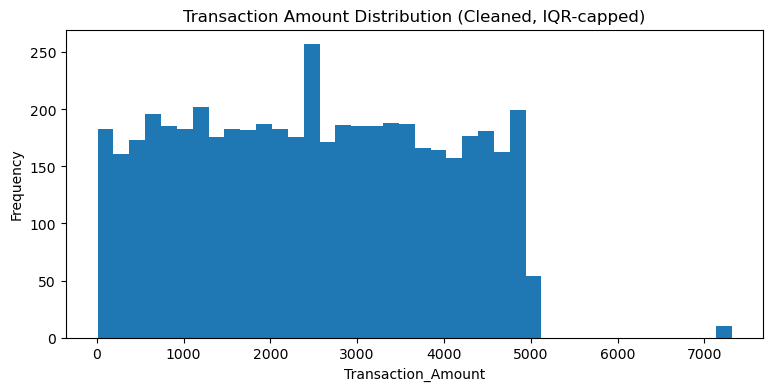

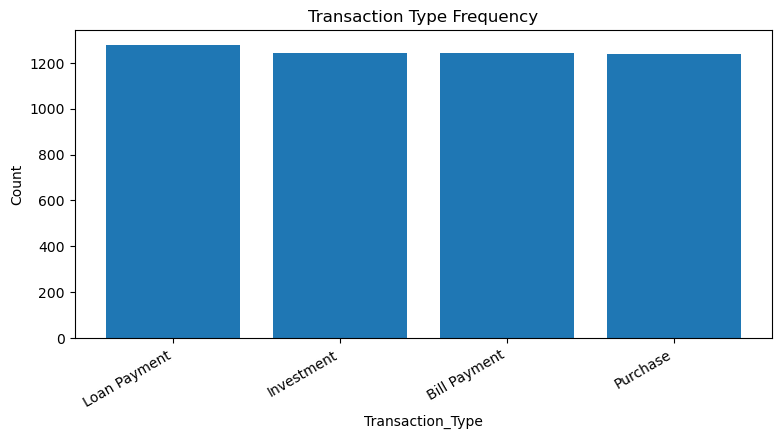

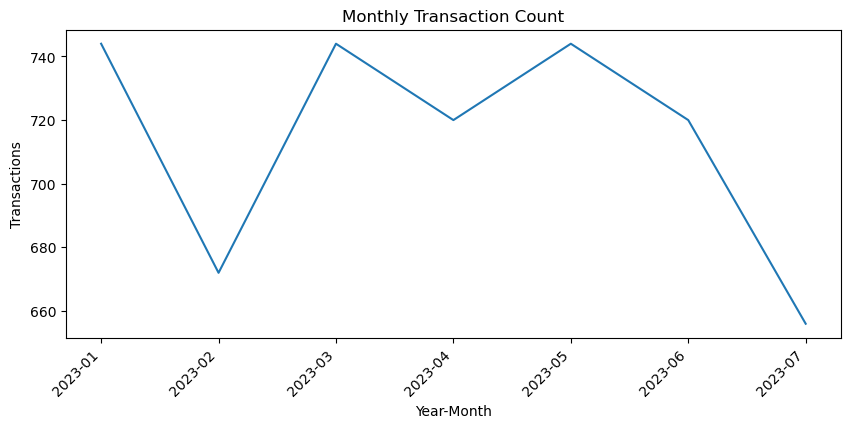

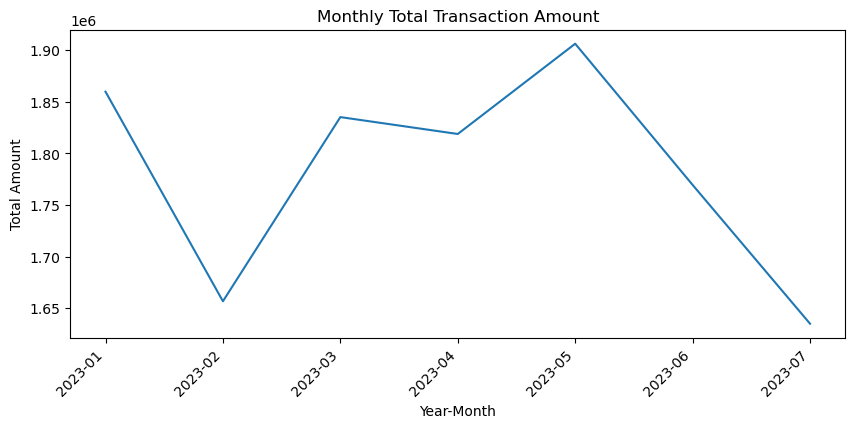

,Transaction_Amount,amount_was_missing,amount_outlier_flag
count,"5,000.00","5,000.00","5,000.00"
mean,"2,496.35",0.02,0.00
std,"1,439.23",0.14,0.04
min,10.00,0.00,0.00
25%,"1,260.00",0.00,0.00
50%,"2,485.00",0.00,0.00
75%,"3,682.00",0.00,0.00
max,"7,315.00",1.00,1.00


In [9]:

# Amount distribution (after cleaning + capping)
plt.figure(figsize=(9, 4))
plt.hist(transactions["Transaction_Amount"], bins=40)
plt.title("Transaction Amount Distribution (Cleaned, IQR-capped)")
plt.xlabel("Transaction_Amount")
plt.ylabel("Frequency")
plt.show()

# Transaction type frequency
type_counts = transactions["Transaction_Type"].value_counts().sort_values(ascending=False)
plt.figure(figsize=(9, 4))
plt.bar(type_counts.index, type_counts.values)
plt.title("Transaction Type Frequency")
plt.xlabel("Transaction_Type")
plt.ylabel("Count")
plt.xticks(rotation=30, ha="right")
plt.show()

# Monthly trends
txn_month = transactions.copy()
txn_month["YearMonth"] = txn_month["Transaction_Date"].dt.to_period("M").astype(str)

monthly = txn_month.groupby("YearMonth").agg(
    txn_count=("Transaction_ID", "size"),
    txn_amount_sum=("Transaction_Amount", "sum"),
).reset_index()

plt.figure(figsize=(10, 4))
plt.plot(monthly["YearMonth"], monthly["txn_count"])
plt.title("Monthly Transaction Count")
plt.xlabel("Year-Month")
plt.ylabel("Transactions")
plt.xticks(rotation=45, ha="right")
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(monthly["YearMonth"], monthly["txn_amount_sum"])
plt.title("Monthly Total Transaction Amount")
plt.xlabel("Year-Month")
plt.ylabel("Total Amount")
plt.xticks(rotation=45, ha="right")
plt.show()

display(transactions[["Transaction_Amount", "amount_was_missing", "amount_outlier_flag"]].describe().round(2))


### 5.2 Customer feedback EDA

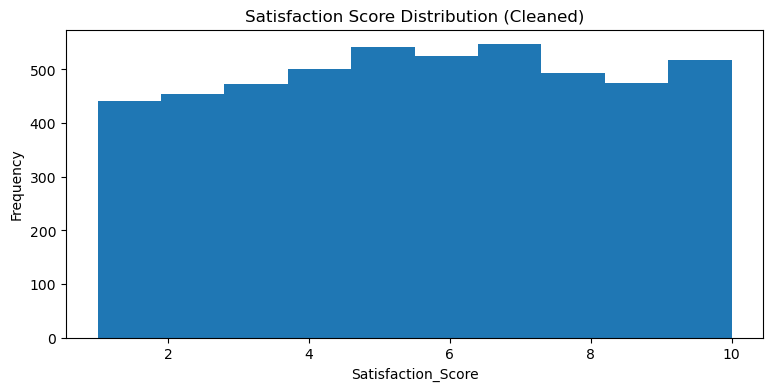

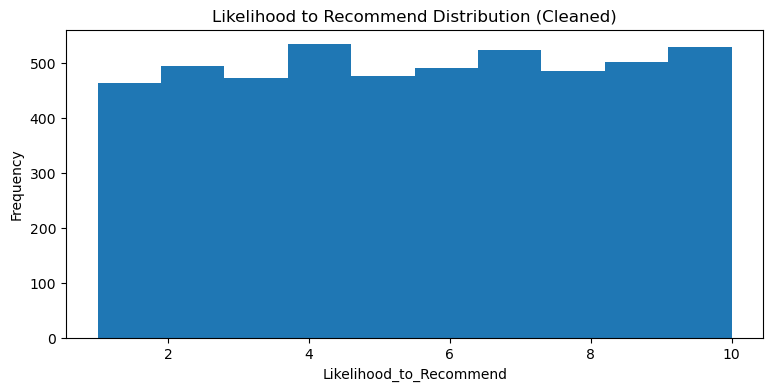

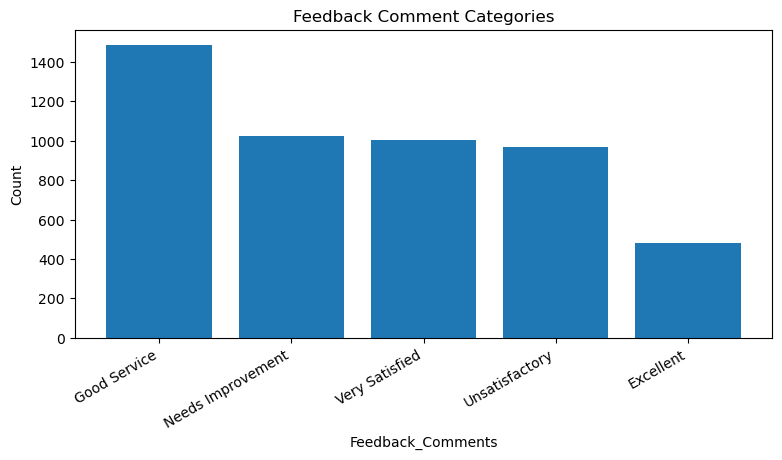

,Customer_ID,feedback_count,satisfaction_mean,satisfaction_std,ltr_mean,ltr_std,top_comment
count,"1,000.00","1,000.00","1,000.00","1,000.00","1,000.00","1,000.00",1000
unique,NaN,NaN,NaN,NaN,NaN,NaN,5
top,NaN,NaN,NaN,NaN,NaN,NaN,Good Service
freq,NaN,NaN,NaN,NaN,NaN,NaN,352
mean,500.50,4.97,5.61,2.61,5.57,2.62,NaN
std,288.82,1.98,1.40,0.98,1.45,0.98,NaN
min,1.00,1.00,1.00,0.00,1.00,0.00,NaN
25%,250.75,4.00,4.75,2.07,4.57,2.08,NaN
50%,500.50,5.00,5.60,2.70,5.67,2.73,NaN
75%,750.25,6.00,6.50,3.27,6.50,3.30,NaN


In [10]:

# Satisfaction distribution
plt.figure(figsize=(9, 4))
plt.hist(feedback["Satisfaction_Score"], bins=10)
plt.title("Satisfaction Score Distribution (Cleaned)")
plt.xlabel("Satisfaction_Score")
plt.ylabel("Frequency")
plt.show()

# Likelihood to recommend distribution
plt.figure(figsize=(9, 4))
plt.hist(feedback["Likelihood_to_Recommend"], bins=10)
plt.title("Likelihood to Recommend Distribution (Cleaned)")
plt.xlabel("Likelihood_to_Recommend")
plt.ylabel("Frequency")
plt.show()

# Comment category counts
comment_counts = feedback["Feedback_Comments"].value_counts()
plt.figure(figsize=(9, 4))
plt.bar(comment_counts.index, comment_counts.values)
plt.title("Feedback Comment Categories")
plt.xlabel("Feedback_Comments")
plt.ylabel("Count")
plt.xticks(rotation=30, ha="right")
plt.show()

display(feedback_agg.describe(include="all").round(2))


### 5.3 Product offering EDA

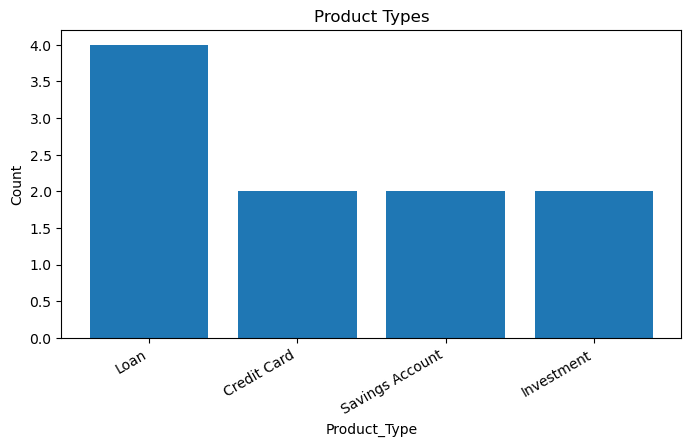

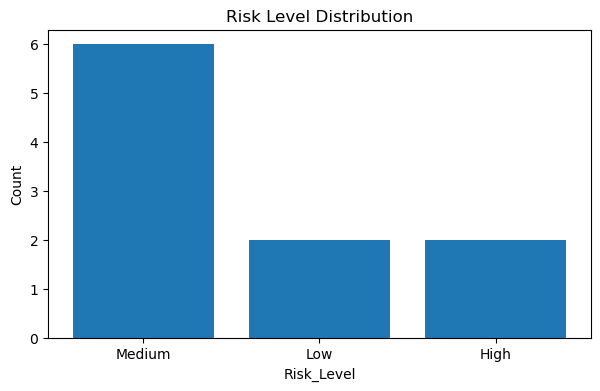

,Product_ID,Product_Name,Product_Type,Risk_Level,Target_Income_Group
0,1,Platinum Credit Card,Credit Card,Medium,Medium
1,2,Gold Savings Account,Savings Account,Low,Low
2,3,High-Yield Investment Account,Investment,High,High
3,4,Mortgage Loan,Loan,Medium,High
4,5,Auto Loan,Loan,Medium,Medium
5,6,Personal Loan,Loan,Medium,Low
6,7,Youth Savings Account,Savings Account,Low,Low
7,8,Retirement Investment Fund,Investment,High,High
8,9,Business Loan,Loan,Medium,Medium
9,10,Travel Credit Card,Credit Card,Medium,Medium


In [11]:

if "Product_Type" in products.columns:
    pt = products["Product_Type"].value_counts()
    plt.figure(figsize=(8, 4))
    plt.bar(pt.index, pt.values)
    plt.title("Product Types")
    plt.xlabel("Product_Type")
    plt.ylabel("Count")
    plt.xticks(rotation=30, ha="right")
    plt.show()

if "Risk_Level" in products.columns:
    rl = products["Risk_Level"].value_counts()
    plt.figure(figsize=(7, 4))
    plt.bar(rl.index, rl.values)
    plt.title("Risk Level Distribution")
    plt.xlabel("Risk_Level")
    plt.ylabel("Count")
    plt.xticks(rotation=0)
    plt.show()

display(products)


### 5.4 Spend vs satisfaction (customer-level EDA)

To avoid row-multiplication issues, we compute customer-level spend summaries first, then merge with the customer-level feedback summary.


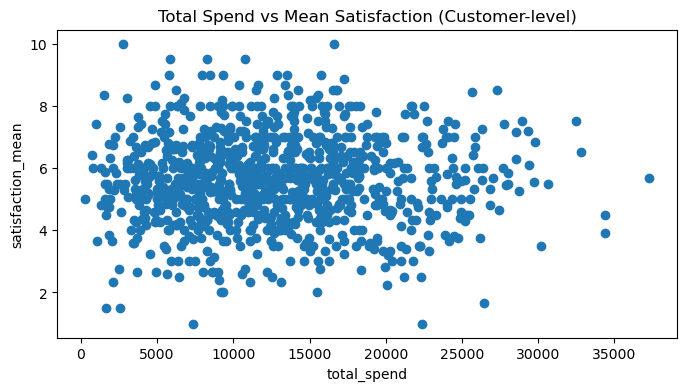

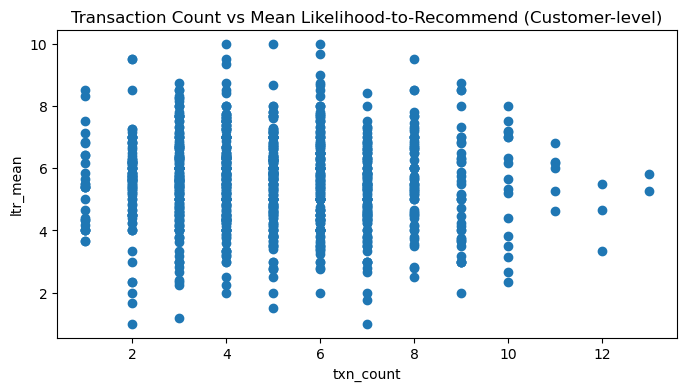

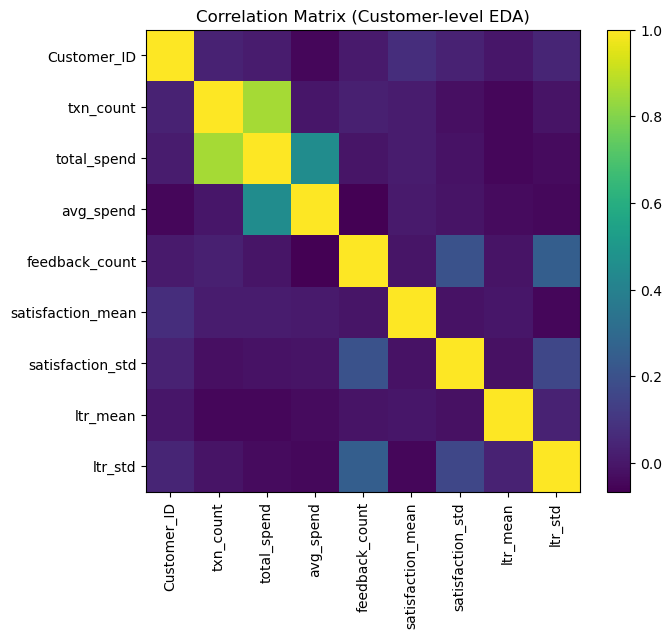

,Customer_ID,txn_count,total_spend,avg_spend,feedback_count,satisfaction_mean,satisfaction_std,ltr_mean,ltr_std
count,993.00,993.00,993.00,993.00,993.00,993.00,993.00,993.00,993.00
mean,500.87,5.04,"12,569.72","2,497.78",4.97,5.61,2.60,5.57,2.62
std,288.63,2.19,"6,424.66",758.16,1.98,1.41,0.98,1.46,0.98
min,1.00,1.00,286.00,286.00,1.00,1.00,0.00,1.00,0.00
25%,251.00,3.00,"7,777.00","2,015.00",4.00,4.75,2.07,4.57,2.08
50%,502.00,5.00,"11,939.00","2,458.67",5.00,5.60,2.70,5.67,2.72
75%,750.00,6.00,"16,531.00","2,930.75",6.00,6.50,3.25,6.50,3.30
max,"1,000.00",13.00,"37,281.00","4,993.00",13.00,10.00,6.36,10.00,6.36


In [12]:

cust_spend = (
    transactions
    .groupby("Customer_ID", as_index=False)
    .agg(
        txn_count=("Transaction_ID", "size"),
        total_spend=("Transaction_Amount", "sum"),
        avg_spend=("Transaction_Amount", "mean"),
    )
)

cust_eda = cust_spend.merge(feedback_agg, on="Customer_ID", how="left")

plt.figure(figsize=(8, 4))
plt.scatter(cust_eda["total_spend"], cust_eda["satisfaction_mean"])
plt.title("Total Spend vs Mean Satisfaction (Customer-level)")
plt.xlabel("total_spend")
plt.ylabel("satisfaction_mean")
plt.show()

plt.figure(figsize=(8, 4))
plt.scatter(cust_eda["txn_count"], cust_eda["ltr_mean"])
plt.title("Transaction Count vs Mean Likelihood-to-Recommend (Customer-level)")
plt.xlabel("txn_count")
plt.ylabel("ltr_mean")
plt.show()

numeric_cols = cust_eda.select_dtypes(include=[np.number]).columns
corr = cust_eda[numeric_cols].corr()

plt.figure(figsize=(7, 6))
plt.imshow(corr, aspect="auto")
plt.title("Correlation Matrix (Customer-level EDA)")
plt.xticks(range(len(numeric_cols)), numeric_cols, rotation=90)
plt.yticks(range(len(numeric_cols)), numeric_cols)
plt.colorbar()
plt.show()

display(cust_eda.describe().round(2))


## 6) Export cleaned datasets

### Export choices (for consistency in submission)
- Save to a dedicated folder: **`cleaned/`**
- Use simple filenames (no timestamps) so it is easier to locate files
- Round numeric columns to **2 decimals** for clean presentation

> Note: If you later need maximum numeric precision for modeling, you can export an additional “full precision” version in the feature engineering notebook.


In [13]:

out_dir = Path("cleaned")
out_dir.mkdir(exist_ok=True)

# Round numeric fields for clean-looking exports
transactions_export = transactions.copy()
feedback_export = feedback.copy()
feedback_agg_export = feedback_agg.copy()
products_export = products.copy()
merged_export = merged.copy()

def round_numeric(df: pd.DataFrame, decimals: int = 2) -> pd.DataFrame:
    out = df.copy()
    num_cols = out.select_dtypes(include=[np.number]).columns
    out[num_cols] = out[num_cols].round(decimals)
    return out

transactions_export = round_numeric(transactions_export, 2)
feedback_export = round_numeric(feedback_export, 2)
feedback_agg_export = round_numeric(feedback_agg_export, 2)
products_export = round_numeric(products_export, 2)
merged_export = round_numeric(merged_export, 2)

transactions_out = out_dir / "transactions_cleaned.csv"
feedback_out     = out_dir / "feedback_cleaned.csv"
feedbackagg_out  = out_dir / "feedback_customer_summary.csv"
products_out     = out_dir / "products_cleaned.csv"
merged_out       = out_dir / "merged_transactions_feedback.csv"

transactions_export.to_csv(transactions_out, index=False)
feedback_export.to_csv(feedback_out, index=False)
feedback_agg_export.to_csv(feedbackagg_out, index=False)
products_export.to_csv(products_out, index=False)
merged_export.to_csv(merged_out, index=False)

print("Saved cleaned datasets:")
print("-", transactions_out)
print("-", feedback_out)
print("-", feedbackagg_out)
print("-", products_out)
print("-", merged_out)


Saved cleaned datasets:
- cleaned/transactions_cleaned.csv
- cleaned/feedback_cleaned.csv
- cleaned/feedback_customer_summary.csv
- cleaned/products_cleaned.csv
- cleaned/merged_transactions_feedback.csv


## 7) Summary of process and key insights

### What happened in this notebook (end-to-end)
- **Loaded** the three FinMark datasets and performed a data quality audit (missingness, dtypes, duplicates).  
- **Cleaned** each dataset using consistent rules and tracked what was changed (duplicates removed, missing values imputed, outliers treated).  
- **Standardized** formats:
  - parsed transaction dates into datetime  
  - enforced numeric types for amounts and score fields  
  - normalized category text (e.g., transaction type, feedback comments)  
- **Integrated** transactions with a **customer-level feedback summary** to support EDA without inflating records.  
- **Produced EDA visuals** that describe distributions, category frequencies, trends over time, and spend-vs-satisfaction relationships.

### Key cleaning decisions (and why they are defensible)
- **Duplicates:** dropped full-row duplicates to prevent double counting and biased summary statistics.  
- **Missing values:** imputed using **group-aware medians** where possible (e.g., transaction type / customer median) to preserve natural scale.  
- **Outliers:** capped transaction amounts using IQR bounds to reduce distortion in EDA while preserving dataset size.

### Key findings from EDA (high-level)
- Transaction activity can be profiled by:
  - **amount distribution** (typical range vs extremes after capping)  
  - **transaction type mix** (most frequent transaction categories)  
  - **time patterns** (monthly variability in transaction counts and total amounts)  
- Customer feedback can be summarized by:
  - average satisfaction and recommendation scores per customer  
  - stability/variability of feedback (std dev)  
  - most common feedback theme (top comment category)  
- Early relationship checks at customer level allow an initial view of:
  - whether higher spend correlates with satisfaction/recommendation  
  - whether frequency of transactions relates to recommendation tendency  

### What this enables next
The cleaned outputs in `cleaned/` provide a stable input layer for a dedicated feature engineering notebook, where we can create a clustering-ready customer feature table and apply scaling/normalization for segmentation models.
